# FNO predictions at different resolutions

Choose one evaluation example below. Each panel compares the input field, the true next-step solution, and the FNO prediction.

In [2]:
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

EXAMPLE_INDEX = 0
RESOLUTIONS = (128, 256, 512)

# Works when this notebook is run from either the project root or FNO_submission/.
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'data').is_dir():
    PROJECT_DIR = PROJECT_DIR.parent
DATA_DIR = PROJECT_DIR / 'data'
CHECKPOINT_PATH = PROJECT_DIR / 'FNO_submission' / 'fno_modes64_all48_seed0.pt'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [3]:
class SpectralConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, modes):
        super().__init__()
        self.modes = modes
        scale = 1 / (in_channels * out_channels)
        self.weights = nn.Parameter(
            scale * torch.randn(in_channels, out_channels, modes, dtype=torch.cfloat)
        )

    def forward(self, x):
        batch, _, n_points = x.shape
        x_freq = torch.fft.rfft(x)
        out_freq = torch.zeros(
            batch, self.weights.shape[1], n_points // 2 + 1,
            dtype=torch.cfloat, device=x.device
        )
        modes = min(self.modes, n_points // 2 + 1)
        out_freq[:, :, :modes] = torch.einsum(
            'bix,iox->box', x_freq[:, :, :modes], self.weights[:, :, :modes]
        )
        return torch.fft.irfft(out_freq, n=n_points)


class FNO1d(nn.Module):
    def __init__(self, modes=64, width=64, n_layers=4):
        super().__init__()
        self.lift = nn.Linear(2, width)
        self.spec = nn.ModuleList([
            SpectralConv1d(width, width, modes) for _ in range(n_layers)
        ])
        self.w = nn.ModuleList([
            nn.Conv1d(width, width, 1) for _ in range(n_layers)
        ])
        self.proj = nn.Sequential(
            nn.Linear(width, 128), nn.GELU(), nn.Linear(128, 1)
        )

    def forward(self, x):
        x = self.lift(x).permute(0, 2, 1)
        for spectral, pointwise in zip(self.spec, self.w):
            x = nn.functional.gelu(spectral(x) + pointwise(x))
        return self.proj(x.permute(0, 2, 1)).squeeze(-1)


def make_input(field):
    batch, n_points = field.shape
    x = torch.linspace(0, 1, n_points + 1, device=field.device)[:-1]
    x = x.expand(batch, n_points)
    return torch.stack((field, x), dim=-1)


checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)
model = FNO1d(**checkpoint['config']).to(DEVICE)
model.load_state_dict(checkpoint['state'])
model.eval()
print(f'Loaded model on {DEVICE}')

Loaded model on cpu


In [4]:
predictions = {}
for resolution in RESOLUTIONS:
    with np.load(DATA_DIR / f'eval_{resolution}.npz') as data:
        fields = data['field'].astype(np.float32)
        targets = data['target'].astype(np.float32)
        coordinates = data['coordinates']

    if not 0 <= EXAMPLE_INDEX < len(fields):
        raise IndexError(f'EXAMPLE_INDEX must be between 0 and {len(fields) - 1}')

    field = torch.from_numpy(fields[EXAMPLE_INDEX:EXAMPLE_INDEX + 1]).to(DEVICE)
    with torch.no_grad():
        prediction = model(make_input(field)).cpu().numpy()[0]

    target = targets[EXAMPLE_INDEX]
    relative_error = np.linalg.norm(prediction - target) / (np.linalg.norm(target) + 1e-8)
    predictions[resolution] = (coordinates, fields[EXAMPLE_INDEX], target, prediction, relative_error)

print(f'Plotting evaluation example {EXAMPLE_INDEX}')

Plotting evaluation example 0


Saved /Users/vedbhatt/Desktop/AML/learning-physical-dynamics-across-resolutions-main 6.08.58 PM/FNO_submission/plots_outputs.png


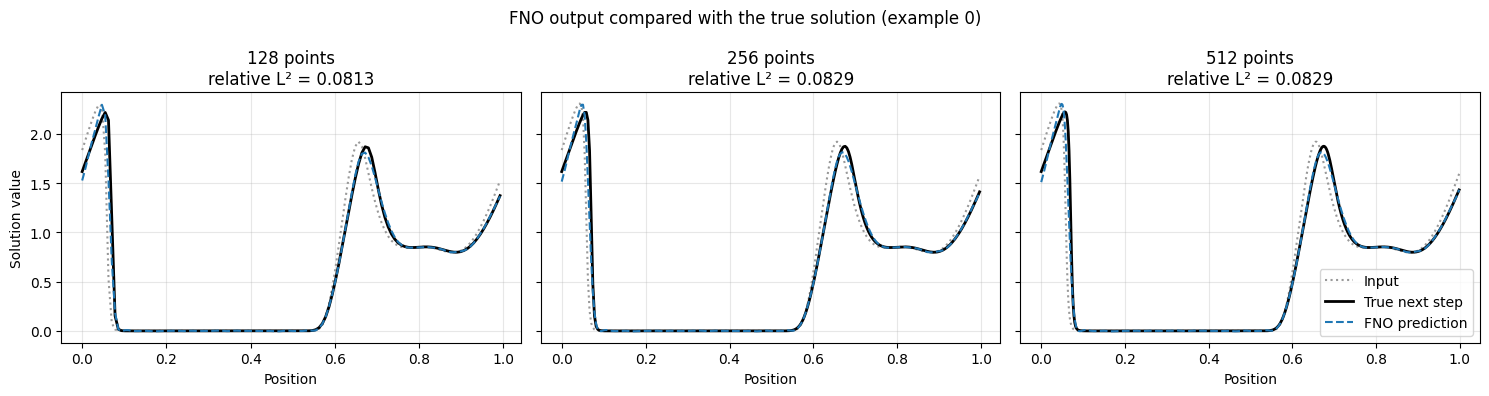

In [5]:
fig, axes = plt.subplots(1, len(RESOLUTIONS), figsize=(15, 4), sharey=True)

for ax, resolution in zip(axes, RESOLUTIONS):
    x, field, target, prediction, relative_error = predictions[resolution]
    ax.plot(x, field, color='0.6', linestyle=':', label='Input')
    ax.plot(x, target, color='black', linewidth=2, label='True next step')
    ax.plot(x, prediction, color='C0', linestyle='--', label='FNO prediction')
    ax.set_title(f'{resolution} points\nrelative L² = {relative_error:.4f}')
    ax.set_xlabel('Position')
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('Solution value')
axes[-1].legend()
fig.suptitle(f'FNO output compared with the true solution (example {EXAMPLE_INDEX})')
fig.tight_layout()
output_path = PROJECT_DIR / 'FNO_submission' / 'plots_outputs.png'
fig.savefig(output_path, dpi=150, bbox_inches='tight')
print(f'Saved {output_path}')